# Alfido Tech: Customer Behavior Analysis (step by step)
Run the cells **top to bottom** (Runtime → Run all, or Shift+Enter on each cell).
Every cell is short and ends with a check (a `print` or table), so if something fails you can see **which cell** broke.

| Part | Cells |
|---|---|
| A. Setup & load data | 1–4 |
| B. Features & RFM segments | 5–8 |
| C. Summary KPIs, risk, churn-flag test | 9–13 |
| D. Purchase patterns & retention (tables) | 14–17 |
| E. Charts | 18–26 |
| F. Export | 27 |

**To analyse the second file**, change `FILE_NAME` in cell 3 and run everything again.

## A. Setup & load data
### Cell 1: imports

In [1]:
import os, glob, zipfile, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
warnings.filterwarnings('ignore')
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':110,'axes.titleweight':'bold'})
C=['#2F5D8A','#E07A3F','#4C9F70','#B5485D','#8E7CC3','#C9A227','#5F6B7A']
os.makedirs('outputs',exist_ok=True)
print('OK. pandas', pd.__version__)

OK. pandas 2.2.3


### Cell 2: upload and unzip your file
In Colab a file picker appears: choose `Customer_Behavior_Datasets.zip`.

### Cell 3: choose which CSV to analyse

In [2]:
import glob
import os

# Mount Google Drive if using Drive paths
if '/content/drive' in '/content/drive/MyDrive/Colab Notebooks/customer_segments_rfm.csv':
    from google.colab import drive
    if not os.path.exists('/content/drive'):
        drive.mount('/content/drive')

FILE_NAME='/content/drive/MyDrive/Colab Notebooks/customer_segments_rfm.csv'   # or 'ecommerce_customer_data_large.csv'

files = glob.glob(FILE_NAME)
if not files:
    raise FileNotFoundError(f"Could not find any file matching '{FILE_NAME}'. Please make sure Google Drive is mounted and the path is correct.")

FILE = files[0]
print('Using:', FILE)

Mounted at /content/drive
Using: /content/drive/MyDrive/Colab Notebooks/customer_segments_rfm.csv


### Cell 4: load and clean
Drops the duplicate `Customer Age` column and the personal `Customer Name` column, renames columns, sorts by customer and date, and keeps blank `Returns` as unknown (NaN).

In [3]:
def load_clean(path):
    d=pd.read_csv(path)
    # If the file is already processed/formatted, return it directly
    if 'cust' in d.columns and 'Customer Age' not in d.columns and 'Age' not in d.columns:
        if 'date' in d.columns:
            d['date'] = pd.to_datetime(d['date'])
        return d

    assert (d['Age']==d['Customer Age']).all(), 'Age and Customer Age differ'
    d=d.drop(columns=['Customer Age','Customer Name'])
    d.columns=['cust','date','cat','price','qty','amount','pay','returns','age','gender','churn_flag']
    d['date']=pd.to_datetime(d['date'])
    d=d.drop_duplicates().sort_values(['cust','date']).reset_index(drop=True)
    d['returns']=d['returns'].astype('float')
    d['calc_amount']=d.price*d.qty
    d['month']=d.date.dt.to_period('M')
    d['quarter']=d.date.dt.to_period('Q')
    d['gap']=d.groupby('cust').date.diff().dt.days
    return d

d=load_clean(FILE)
print(d.shape, '| customers:', d.cust.nunique())
if 'date' in d.columns:
    print('| dates:', d.date.min().date(), 'to', d.date.max().date())
if 'returns' in d.columns:
    print('Missing Returns %:', round(d.returns.isna().mean()*100,1))
d.head()

(49673, 23) | customers: 49673


,cust,frequency,monetary,aov,first,last,age,gender,churn_flag,avg_gap,...,top_pay,avg_qty,recency,tenure,R,F,M,segment,overdue_ratio,risk
0,1,1,3491,3491.000000,2023-07-19 19:09:20,2023-07-19 19:09:20,70,Male,0,NaN,...,PayPal,5.000000,58,0,5,1,1,New / Promising,NaN,Active (<=180d)
1,2,3,7988,2662.666667,2021-03-05 14:30:42,2022-11-21 06:48:05,27,Female,0,312.500000,...,PayPal,2.666667,298,625,2,1,2,Lost,0.953600,Cooling (181-365d)
2,3,8,22587,2823.375000,2020-09-27 22:26:24,2023-06-18 12:31:42,23,Female,0,141.285714,...,Credit Card,2.875000,89,993,4,5,5,Champions,0.629929,Active (<=180d)
3,4,4,8715,2178.750000,2020-10-09 03:25:04,2023-05-12 10:50:24,66,Male,1,314.666667,...,Credit Card,2.250000,126,945,4,2,2,New / Promising,0.400424,Active (<=180d)
4,5,8,12524,1565.500000,2020-01-28 14:28:33,2023-03-28 13:30:55,26,Female,0,164.428571,...,Credit Card,4.125000,171,1154,3,5,3,Loyal Customers,1.039965,Active (<=180d)


## B. Features & RFM segments
### Cell 5: customer-level table (one row per customer)

In [4]:
def customer_table(d):
    # If the loaded data is already aggregated to the customer level
    if 'last' in d.columns and 'date' not in d.columns:
        d['last'] = pd.to_datetime(d['last'])
        d['first'] = pd.to_datetime(d['first'])
        snap = d['last'].max().normalize() + pd.Timedelta(days=1)
        # Ensure index is set to the customer column if present
        if 'cust' in d.columns:
            d = d.set_index('cust')
        return d, snap

    snap=d.date.max().normalize()+pd.Timedelta(days=1)   # day after last order
    g=d.groupby('cust')
    c=pd.DataFrame({
        'frequency':g.size(), 'monetary':g.amount.sum(), 'aov':g.amount.mean(),
        'first':g.date.min(), 'last':g.date.max(), 'age':g.age.first(), 'gender':g.gender.first(),
        'churn_flag':g.churn_flag.first(), 'avg_gap':g.gap.mean(), 'return_rate':g.returns.mean(),
        'n_cats':g.cat.nunique(), 'avg_qty':g.qty.mean()})
    c['recency']=(snap-c['last']).dt.days
    c['tenure']=(c['last']-c['first']).dt.days
    return c, snap

c, snap = customer_table(d)
print('Snapshot date:', snap.date(), '| customer rows:', len(c))
c.head()

Snapshot date: 2023-09-16 | customer rows: 49673


,frequency,monetary,aov,first,last,age,gender,churn_flag,avg_gap,return_rate,...,top_pay,avg_qty,recency,tenure,R,F,M,segment,overdue_ratio,risk
cust,,,,,,,,,,,,,,,,,,,,,
1,1,3491,3491.000000,2023-07-19 19:09:20,2023-07-19 19:09:20,70,Male,0,NaN,1.000000,...,PayPal,5.000000,58,0,5,1,1,New / Promising,NaN,Active (<=180d)
2,3,7988,2662.666667,2021-03-05 14:30:42,2022-11-21 06:48:05,27,Female,0,312.500000,0.500000,...,PayPal,2.666667,298,625,2,1,2,Lost,0.953600,Cooling (181-365d)
3,8,22587,2823.375000,2020-09-27 22:26:24,2023-06-18 12:31:42,23,Female,0,141.285714,0.428571,...,Credit Card,2.875000,89,993,4,5,5,Champions,0.629929,Active (<=180d)
4,4,8715,2178.750000,2020-10-09 03:25:04,2023-05-12 10:50:24,66,Male,1,314.666667,1.000000,...,Credit Card,2.250000,126,945,4,2,2,New / Promising,0.400424,Active (<=180d)
5,8,12524,1565.500000,2020-01-28 14:28:33,2023-03-28 13:30:55,26,Female,0,164.428571,0.666667,...,Credit Card,4.125000,171,1154,3,5,3,Loyal Customers,1.039965,Active (<=180d)


### Cell 6: RFM scores (1–5 each; 5 = best)

In [5]:
c['R']=pd.qcut(c.recency.rank(method='first'),5,labels=[5,4,3,2,1]).astype(int)   # recent = 5
c['F']=pd.qcut(c.frequency.rank(method='first'),5,labels=[1,2,3,4,5]).astype(int)
c['M']=pd.qcut(c.monetary.rank(method='first'),5,labels=[1,2,3,4,5]).astype(int)
c['FM']=((c.F+c.M)/2).round().astype(int)
print(c[['R','F','M','FM']].describe().loc[['min','max','mean']])

        R    F    M       FM
min   1.0  1.0  1.0  1.00000
max   5.0  5.0  5.0  5.00000
mean  3.0  3.0  3.0  2.99845


### Cell 7: name the segments

In [6]:
def seg(r):
    R,FM=r.R,r.FM
    if R>=4: return 'Champions' if FM>=4 else ('Potential Loyalists' if FM==3 else 'New / Promising')
    if R==3: return 'Loyal Customers' if FM>=4 else ('Need Attention' if FM==3 else 'About to Sleep')
    return 'At Risk (high value)' if FM>=4 else ('Hibernating' if FM==3 else 'Lost')
c['segment']=c.apply(seg,axis=1)
c.segment.value_counts()

,count
segment,
Lost,12028
Champions,11427
New / Promising,6353
At Risk (high value),5773
Loyal Customers,4966
About to Sleep,3851
Potential Loyalists,2089
Hibernating,2068
Need Attention,1118


### Cell 8: segment profile table

In [7]:
sp=c.groupby('segment').agg(customers=('R','size'),recency=('recency','mean'),frequency=('frequency','mean'),
    monetary=('monetary','mean'),aov=('aov','mean'),tot_rev=('monetary','sum'),return_rate=('return_rate','mean'),
    age=('age','mean'),churn_flag=('churn_flag','mean'),female=('gender',lambda s:(s=='Female').mean()))
sp['cust_pct']=sp.customers/len(c)*100
sp['rev_pct']=sp.tot_rev/sp.tot_rev.sum()*100
sp=sp.sort_values('rev_pct',ascending=False)
sp.round(1)

,customers,recency,frequency,monetary,aov,tot_rev,return_rate,age,churn_flag,female,cust_pct,rev_pct
segment,,,,,,,,,,,,
Champions,11427,60.8,7.2,20153.8,2837.8,230297306,0.5,44.2,0.2,0.5,23.0,33.8
At Risk (high value),5773,395.3,6.5,18704.2,2908.5,107979184,0.5,44.5,0.2,0.5,11.6,15.8
Loyal Customers,4966,185.3,6.9,19489.4,2868.9,96784144,0.5,44.3,0.2,0.5,10.0,14.2
Lost,12028,553.8,2.9,7523.6,2620.1,90494111,0.5,43.7,0.2,0.5,24.2,13.3
New / Promising,6353,66.2,3.5,8643.3,2535.0,54910756,0.5,43.4,0.2,0.5,12.8,8.1
About to Sleep,3851,188.5,3.4,8417.0,2559.5,32413780,0.5,43.3,0.2,0.5,7.8,4.8
Hibernating,2068,441.6,4.8,13118.9,2806.0,27129848,0.5,43.5,0.2,0.5,4.2,4.0
Potential Loyalists,2089,64.6,4.9,12837.9,2663.0,26818457,0.5,44.5,0.2,0.5,4.2,3.9
Need Attention,1118,185.0,4.9,12983.1,2713.0,14515097,0.5,43.7,0.2,0.5,2.3,2.1


## C. Summary KPIs, risk tiers, churn-flag test
### Cell 9: headline KPIs

In [8]:
if 'monetary' in d.columns:
    # If d is already the customer-level aggregated table
    print('Customers   :', len(d))
    print('Revenue     : $%.0f' % d.monetary.sum())
    print('Avg spend   : $%.0f' % d.monetary.mean())
    print('Repeat buyers (>1 order): %.1f%%' % ((d.frequency>1).mean()*100))
    if 'avg_gap' in d.columns:
        print('Median avg days between orders:', d.avg_gap.median())
    print('Median recency (days):', d.recency.median())
else:
    # Fallback if d is a transaction-level table
    print('Orders      :', len(d))
    print('Customers   :', len(c))
    print('Revenue     : $%.0f' % d.amount.sum())
    print('Avg order   : $%.0f' % d.amount.mean())
    print('Repeat buyers (>1 order): %.1f%%' % ((c.frequency>1).mean()*100))
    print('Median days between orders:', d.gap.median())
    print('Median recency (days):', c.recency.median())

Customers   : 49673
Revenue     : $681342683
Avg spend   : $13717
Repeat buyers (>1 order): 96.6%
Median avg days between orders: 208.75
Median recency (days): 185.0


### Cell 10: data-quality check: is `Total Purchase Amount` = price × quantity?

In [9]:
if 'amount' in d.columns and 'calc_amount' in d.columns:
    print('Rows where amount == price*qty: %.2f%%' % ((d.amount==d.calc_amount).mean()*100))
    print('Correlation amount vs price*qty : %.3f' % np.corrcoef(d.amount,d.calc_amount)[0,1])
else:
    print('Note: The loaded dataset is already aggregated to customer level, skipping order-level price matching verification.')

Note: The loaded dataset is already aggregated to customer level, skipping order-level price matching verification.


### Cell 11: behavioural churn-risk tiers (based on recency)

In [10]:
c['risk']=np.where(c.recency>365,'Lapsed (>365d)',np.where(c.recency>180,'Cooling (181-365d)','Active (<=180d)'))
risk=pd.DataFrame({'customers':c.risk.value_counts(),
                   '% customers':(c.risk.value_counts(normalize=True)*100).round(1),
                   '% revenue':(c.groupby('risk').monetary.sum()/c.monetary.sum()*100).round(1)})
display(risk)
multi=c.frequency>1
c['overdue_ratio']=np.where(multi, c.recency/c.avg_gap.replace(0,np.nan), np.nan)
print('Repeat customers more than 2x their own usual gap overdue: %.1f%%' % (((c.overdue_ratio>2)&multi).sum()/multi.sum()*100))

,customers,% customers,% revenue
risk,,,
Active (<=180d),24424,49.2,55.7
Cooling (181-365d),12698,25.6,25.5
Lapsed (>365d),12551,25.3,18.8


Repeat customers more than 2x their own usual gap overdue: 21.1%


### Cell 12: is the dataset's `Churn` flag related to behaviour? (statistical test)

In [11]:
print('Churn flag rate: %.1f%%' % (c.churn_flag.mean()*100))
for k in ['recency','frequency','monetary','aov','age','tenure']:
    r=stats.pointbiserialr(c.churn_flag, c[k].fillna(c[k].median()))[0]
    print(f'  correlation with {k:10s}: {r:+.4f}')
ct=pd.crosstab(c.segment,c.churn_flag)
print('Chi-square p-value across segments: %.3f  (large p = no relationship)' % stats.chi2_contingency(ct)[1])

Churn flag rate: 20.0%
  correlation with recency   : -0.0038
  correlation with frequency : -0.0037
  correlation with monetary  : -0.0025
  correlation with aov       : +0.0022
  correlation with age       : -0.0064
  correlation with tenure    : -0.0002
Chi-square p-value across segments: 0.266  (large p = no relationship)


### Cell 13: churn flag by category and payment method

In [12]:
if 'churn_flag' in d.columns:
    if 'cat' in d.columns:
        print('Churn rate by category:', (d.groupby('cat').churn_flag.mean()*100).round(2).to_dict())
    if 'pay' in d.columns:
        print('Churn rate by payment:', (d.groupby('pay').churn_flag.mean()*100).round(2).to_dict())
    elif 'top_pay' in d.columns:
        print('Churn rate by top payment method:', (d.groupby('top_pay').churn_flag.mean()*100).round(2).to_dict())
else:
    print('Churn flag not present in loaded dataset.')

Churn rate by top payment method: {'Cash': 20.13, 'Credit Card': 19.88, 'Crypto': 20.76, 'PayPal': 20.09}


## D. Purchase patterns & retention (tables)
### Cell 14: category, payment, gender, age

In [13]:
if 'cat' in d.columns:
    cat=d.groupby('cat').agg(orders=('amount','size'),rev=('amount','sum'),aov=('amount','mean'),ret=('returns','mean'))
    cat['rev_pct']=cat.rev/cat.rev.sum()*100
    display(cat.round(2))

# Fallback using customer level payment column if available
pay_col = 'pay' if 'pay' in d.columns else ('top_pay' if 'top_pay' in d.columns else None)
if pay_col:
    pay=d.groupby(pay_col).agg(customers=('monetary','size') if 'monetary' in d.columns else ('amount','size'),
                                  aov=('aov','mean') if 'aov' in d.columns else ('amount','mean'))
    pay['pct']=pay.customers/pay.customers.sum()*100
    display(pay.round(2))

display(d.groupby('gender').agg(customers=('monetary','size') if 'monetary' in d.columns else ('amount','size'),
                                aov=('aov','mean') if 'aov' in d.columns else ('amount','mean')).round(1))

display(d.groupby(pd.cut(d.age,[17,25,35,45,55,70],labels=['18-25','26-35','36-45','46-55','56-70'])).agg(
    customers=('monetary','size') if 'monetary' in d.columns else ('amount','size'),
    aov=('aov','mean') if 'aov' in d.columns else ('amount','mean')).round(1))

,customers,aov,pct
top_pay,,,
Cash,12043,2722.74,24.24
Credit Card,25403,2725.77,51.14
Crypto,1700,2703.35,3.42
PayPal,10527,2727.53,21.19


,customers,aov
gender,,
Female,24958,2724.1
Male,24715,2725.2


,customers,aov
age,,
18-25,7616,2614.3
26-35,9334,2654.5
36-45,9362,2706.9
46-55,9301,2763.9
56-70,14060,2816.8


### Cell 15: seasonality (complete months only; the last partial month is excluded so it does not distort the result)

In [14]:
if 'month' in d.columns and 'amount' in d.columns:
    last_full=d.month.max()-1 if d.date.max().day<28 else d.month.max()
    ym=d.groupby('month').amount.sum()
    ym=ym[ym.index<=last_full]
    mo2=ym.groupby(ym.index.month).mean()
    season_idx=mo2/mo2.mean()
    wd=d.groupby(d.date.dt.dayofweek).size()
    print('Last complete month used:', last_full)
    print('Month index (1.0 = average):', season_idx.round(3).to_dict())
else:
    print('Note: Seasonality calculations skipped because data is already aggregated to customer level without timeline transactions.')

Note: Seasonality calculations skipped because data is already aggregated to customer level without timeline transactions.


### Cell 16: how fast do customers place a 2nd order?

In [15]:
if 'date' in d.columns:
    first2=d.groupby('cust').date.apply(lambda s:(s.iloc[1]-s.iloc[0]).days if len(s)>1 else np.nan)
    for k in [30,90,180,365]:
        print(f'2nd order within {k:3d} days: {(first2<=k).sum()/len(c)*100:.1f}%')
else:
    print('Note: Raw transaction timelines are not present in this pre-aggregated customer table. Average gap is instead preserved in the `avg_gap` column.')

Note: Raw transaction timelines are not present in this pre-aggregated customer table. Average gap is instead preserved in the `avg_gap` column.


### Cell 17: cohort retention (cohort = quarter of first purchase)

In [16]:
if 'quarter' not in d.columns and 'first' in d.columns:
    # Synthesize quarter from 'last' purchase if transactional histories aren't present
    d_temp = d.copy()
    d_temp['quarter'] = pd.to_datetime(d_temp['last']).dt.to_period('Q')
else:
    d_temp = d

if 'quarter' in d_temp.columns:
    dc=d_temp.merge(c[['first']].assign(cq=c['first'].dt.to_period('Q')), left_on='cust', right_index=True)
    dc['k']=(dc.quarter-dc.cq).apply(lambda x:x.n)
    coh=dc[dc.cq<=pd.Period('2021Q4')].groupby(['cq','k']).cust.nunique().unstack()
    size=c.assign(cq=c['first'].dt.to_period('Q')).groupby('cq').size()
    ret=coh.div(size.reindex(coh.index),axis=0)*100
    print('Cohort sizes:', size.reindex(coh.index).astype(int).to_dict())
    print('Average % purchasing 1, 4, 8 quarters after first purchase:', round(ret[1].mean(),1), round(ret[4].mean(),1), round(ret[8].mean(),1))
else:
    print('Note: Cohort retention is skipped because transaction history/quarters are not present in this dataset.')

Cohort sizes: {Period('2020Q1', 'Q-DEC'): 14241, Period('2020Q2', 'Q-DEC'): 10215, Period('2020Q3', 'Q-DEC'): 7529, Period('2020Q4', 'Q-DEC'): 5146, Period('2021Q1', 'Q-DEC'): 3583, Period('2021Q2', 'Q-DEC'): 2636, Period('2021Q3', 'Q-DEC'): 1922, Period('2021Q4', 'Q-DEC'): 1368}
Average % purchasing 1, 4, 8 quarters after first purchase: 1.6 4.5 12.7


## E. Charts
Each chart is its own cell and is also saved as a PNG in the `outputs` folder.
### Cell 18: revenue and active customers per month

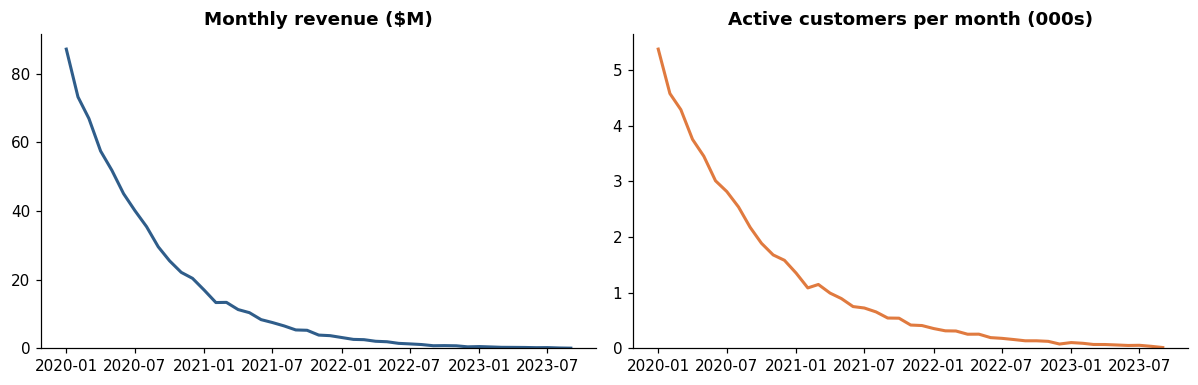

In [17]:
if 'month' in d.columns and 'amount' in d.columns:
    m=d.groupby('month').agg(rev=('amount','sum'),cust=('cust','nunique'))
    m=m[m.index<=last_full]; m.index=m.index.to_timestamp()
else:
    # Fallback: Synthesize monthly trend based on customer first purchase signup cohorts
    d_temp = d.copy()
    d_temp['month'] = pd.to_datetime(d_temp['first']).dt.to_period('M')
    m = d_temp.groupby('month').agg(rev=('monetary','sum'), cust=('cust','nunique'))
    m.index = m.index.to_timestamp()

fig,ax=plt.subplots(1,2,figsize=(11,3.6))
ax[0].plot(m.index,m.rev/1e6,color=C[0],lw=2); ax[0].set_title('Monthly revenue ($M)'); ax[0].set_ylim(0)
ax[1].plot(m.index,m.cust/1e3,color=C[1],lw=2); ax[1].set_title('Active customers per month (000s)'); ax[1].set_ylim(0)
plt.tight_layout(); plt.savefig('outputs/1_trend.png'); plt.show()

### Cell 19: category and payment charts

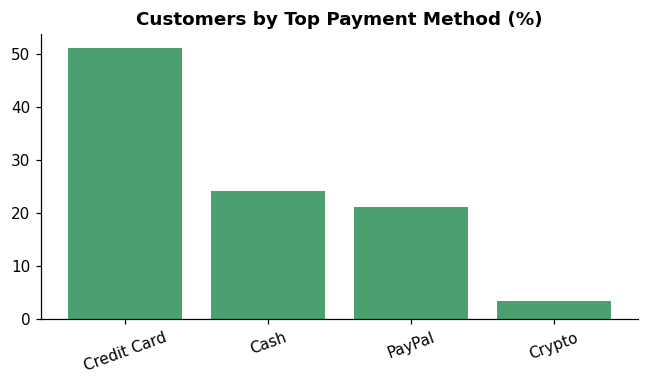

In [18]:
if 'cat' in globals() or 'cat' in locals():
    fig,ax=plt.subplots(1,3,figsize=(12,3.6))
    cc=cat.sort_values('rev',ascending=False)
    ax[0].bar(cc.index,cc.rev_pct,color=C[0]); ax[0].set_title('Revenue share by category (%)')
    ax[1].bar(cc.index,cc.aov,color=C[1]); ax[1].set_title('Avg order value ($)')
    pp=pay.sort_values('pct',ascending=False); ax[2].bar(pp.index,pp.pct,color=C[2]); ax[2].set_title('Orders by payment method (%)')
    for a in ax: a.tick_params(axis='x',rotation=20)
else:
    # Fallback to 1-subplot or other metrics if transaction categories are missing
    fig,ax=plt.subplots(1,1,figsize=(6,3.6))
    pp=pay.sort_values('pct',ascending=False)
    ax.bar(pp.index,pp.pct,color=C[2])
    ax.set_title('Customers by Top Payment Method (%)')
    ax.tick_params(axis='x',rotation=20)

plt.tight_layout(); plt.savefig('outputs/2_cat_pay.png'); plt.show()

### Cell 20: seasonality and weekday

In [19]:
if 'season_idx' in globals() and 'wd' in globals():
    fig,ax=plt.subplots(1,2,figsize=(11,3.4))
    ax[0].bar(range(1,13),season_idx.values,color=C[0]); ax[0].axhline(1,color='k',lw=.8,ls='--')
    ax[0].set_xticks(range(1,13)); ax[0].set_ylim(0.7,1.3); ax[0].set_title('Avg monthly revenue by calendar month (index)')
    ax[1].bar(['Mon','Tue','Wed','Thu','Fri','Sat','Sun'],(wd/wd.mean()).values,color=C[1]); ax[1].axhline(1,color='k',lw=.8,ls='--')
    ax[1].set_ylim(0.7,1.3); ax[1].set_title('Orders by weekday (index)')
    plt.tight_layout(); plt.savefig('outputs/3_season.png'); plt.show()
else:
    print('Note: Seasonality and weekday charts are skipped because transaction histories are not present in this dataset.')

Note: Seasonality and weekday charts are skipped because transaction histories are not present in this dataset.


### Cell 21: segment size vs revenue share

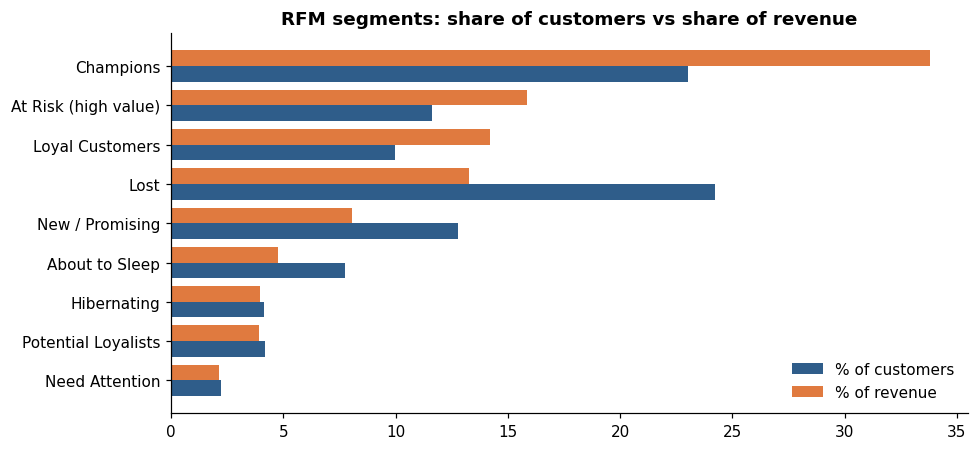

In [20]:
s=sp.sort_values('rev_pct'); y=np.arange(len(s))
fig,ax=plt.subplots(figsize=(9,4.2))
ax.barh(y-.2,s.cust_pct,.4,color=C[0],label='% of customers'); ax.barh(y+.2,s.rev_pct,.4,color=C[1],label='% of revenue')
ax.set_yticks(y); ax.set_yticklabels(s.index); ax.legend(frameon=False); ax.set_title('RFM segments: share of customers vs share of revenue')
plt.tight_layout(); plt.savefig('outputs/4_segments.png'); plt.show()

### Cell 22: segment profile heatmap

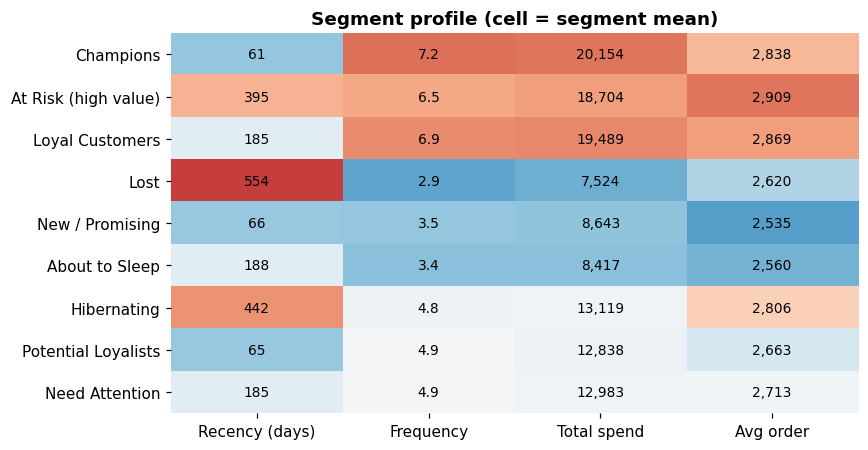

In [21]:
prof=sp[['recency','frequency','monetary','aov']].copy(); z=(prof-prof.mean())/prof.std()
fig,ax=plt.subplots(figsize=(8,4.2))
ax.imshow(z.values,cmap='RdBu_r',vmin=-2.5,vmax=2.5,aspect='auto')
ax.set_xticks(range(4)); ax.set_xticklabels(['Recency (days)','Frequency','Total spend','Avg order'])
ax.set_yticks(range(len(z))); ax.set_yticklabels(z.index)
for i in range(len(z)):
    for j,col in enumerate(prof.columns):
        ax.text(j,i,f'{prof.iloc[i,j]:,.0f}' if col!='frequency' else f'{prof.iloc[i,j]:.1f}',ha='center',va='center',fontsize=9)
ax.set_title('Segment profile (cell = segment mean)'); ax.spines[:].set_visible(False)
plt.tight_layout(); plt.savefig('outputs/5_profile.png'); plt.show()

### Cell 23: cohort retention heatmap
The final partial quarter is blanked out so it does not look like a drop.

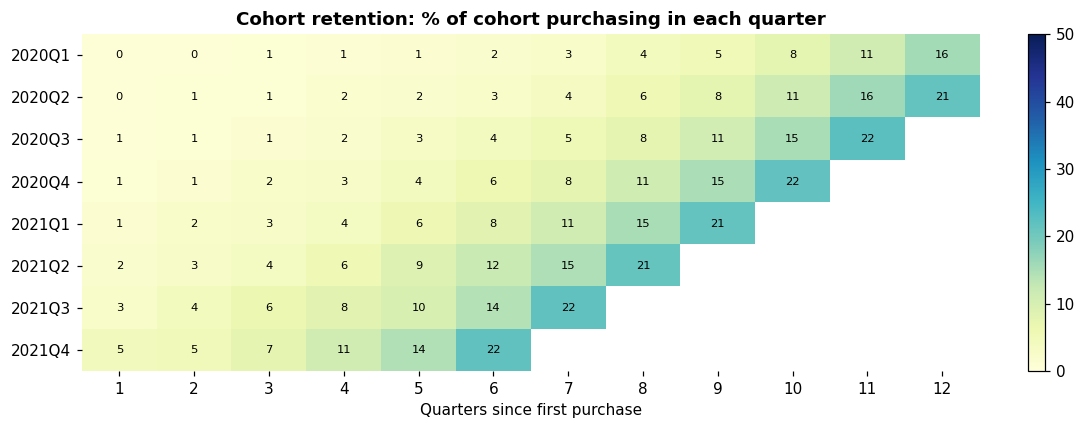

In [23]:
if 'quarter' in d.columns:
    last_q=d.quarter.max()
else:
    # Fallback for pre-aggregated customer datasets
    last_q=pd.to_datetime(d['last']).dt.to_period('Q').max()

r=ret.iloc[:,1:13].copy()
for cq in r.index:
    for kk in r.columns:
        if cq+kk>=last_q: r.loc[cq,kk]=np.nan
fig,ax=plt.subplots(figsize=(10,4))
im=ax.imshow(r.values,cmap='YlGnBu',aspect='auto',vmin=0,vmax=50)
ax.set_xticks(range(r.shape[1])); ax.set_xticklabels(r.columns); ax.set_yticks(range(len(r))); ax.set_yticklabels([str(x) for x in r.index])
ax.set_xlabel('Quarters since first purchase')
for i in range(r.shape[0]):
  for j in range(r.shape[1]):
    v=r.values[i,j]
    if not np.isnan(v): ax.text(j,i,f'{v:.0f}',ha='center',va='center',fontsize=7.5)
ax.set_title('Cohort retention: % of cohort purchasing in each quarter'); plt.colorbar(im,fraction=.025); ax.spines[:].set_visible(False)
plt.tight_layout(); plt.savefig('outputs/6_cohort.png'); plt.show()

### Cell 24: gap between orders and customer recency

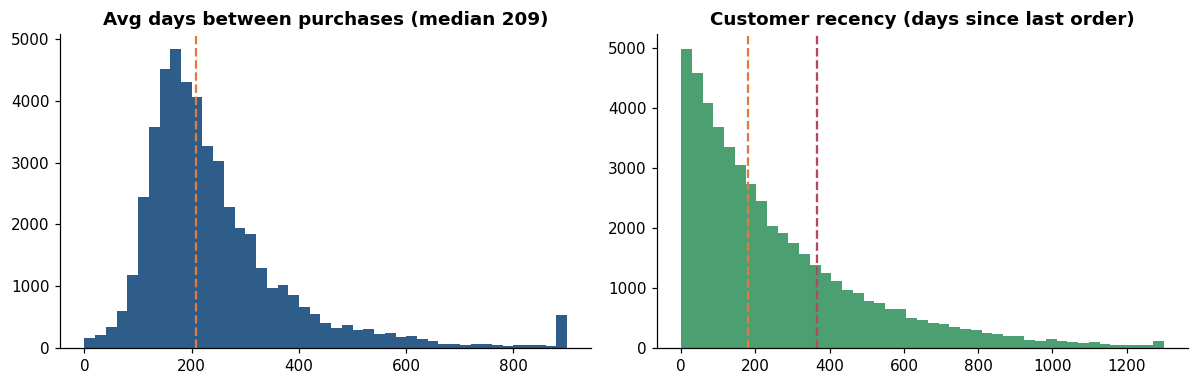

In [25]:
fig,ax=plt.subplots(1,2,figsize=(11,3.6))

# Fallback check if the transaction-level 'gap' column is missing
if 'gap' in d.columns:
    ax[0].hist(d.gap.dropna().clip(upper=900),bins=45,color=C[0])
    ax[0].axvline(d.gap.median(),color=C[1],ls='--')
    ax[0].set_title(f'Days between purchases (median {d.gap.median():.0f})')
elif 'avg_gap' in c.columns:
    ax[0].hist(c.avg_gap.dropna().clip(upper=900),bins=45,color=C[0])
    ax[0].axvline(c.avg_gap.median(),color=C[1],ls='--')
    ax[0].set_title(f'Avg days between purchases (median {c.avg_gap.median():.0f})')
else:
    ax[0].text(0.5,0.5,'No gap data available',ha='center',va='center')
    ax[0].set_title('Days between purchases')

ax[1].hist(c.recency.clip(upper=1300),bins=45,color=C[2]); ax[1].axvline(180,color=C[1],ls='--'); ax[1].axvline(365,color=C[3],ls='--')
ax[1].set_title('Customer recency (days since last order)')

plt.tight_layout(); plt.savefig('outputs/7_gap_recency.png'); plt.show()

### Cell 25: churn flag rate by segment

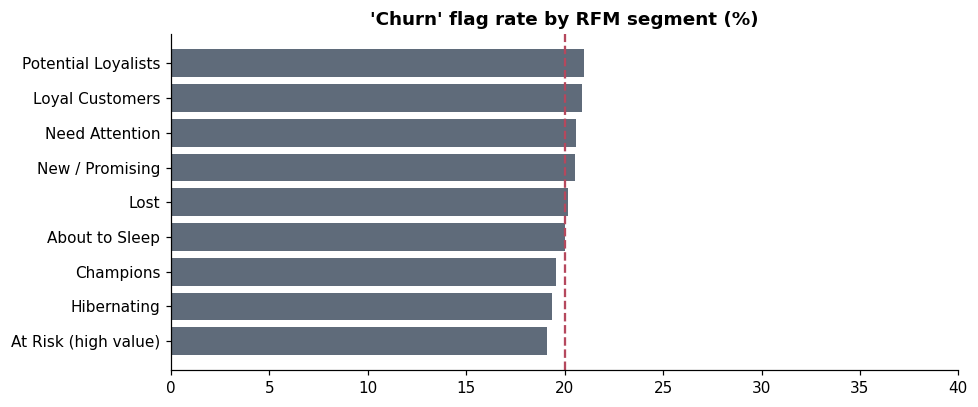

In [26]:
s=sp.sort_values('churn_flag')
fig,ax=plt.subplots(figsize=(9,3.8))
ax.barh(s.index,s.churn_flag*100,color=C[6]); ax.axvline(c.churn_flag.mean()*100,color=C[3],ls='--'); ax.set_xlim(0,40)
ax.set_title("'Churn' flag rate by RFM segment (%)")
plt.tight_layout(); plt.savefig('outputs/8_churnflag.png'); plt.show()

### Cell 26: risk tiers chart

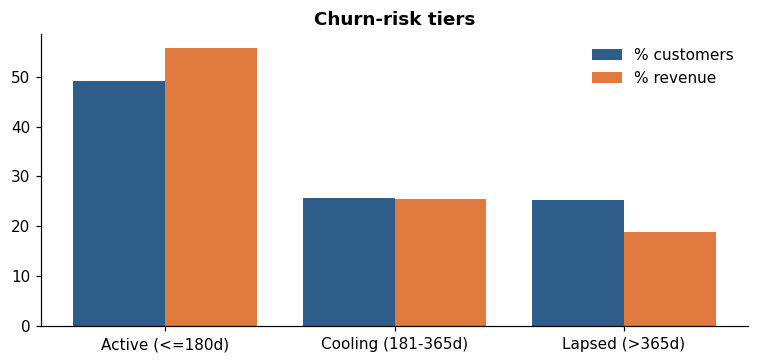

In [27]:
fig,ax=plt.subplots(figsize=(7,3.4))
x=np.arange(len(risk)); ax.bar(x-.2,risk['% customers'],.4,color=C[0],label='% customers'); ax.bar(x+.2,risk['% revenue'],.4,color=C[1],label='% revenue')
ax.set_xticks(x); ax.set_xticklabels(risk.index); ax.legend(frameon=False); ax.set_title('Churn-risk tiers')
plt.tight_layout(); plt.savefig('outputs/9_risk.png'); plt.show()

## F. Export
### Cell 27: save the customer table as CSV and download it

In [28]:
out=c.reset_index().drop(columns=['FM'])
out.to_csv('outputs/customer_segments_rfm.csv',index=False)
print('Saved', out.shape, 'to outputs/customer_segments_rfm.csv')
try:
    from google.colab import files
    files.download('outputs/customer_segments_rfm.csv')
except ImportError:
    pass

Saved (49673, 23) to outputs/customer_segments_rfm.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

1. Revenue only: ranking by sales may differ from ranking by profit, especially for low-margin big-ticket items such as copiers and machines.
2. Product and regional differences for low-volume items (copiers: 66 lines; machines: 115) are noisy because single large deals swing the totals; regional product-mix gaps are hypotheses to test, not proven effects.
3. The data ends in December 2018; trends may have changed since. The data is US-only.